**GitHub Link (contains .ipynb):**  https://github.com/avinashsriram1/ADSP-31011-Statistical-Models-for-Data-Science/tree/main/Assignment%202

# Problem 1

In [2]:
# Setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(123456)

# Baseline parameters
n, mu, sigma, alpha = 30, 1, 1, 0.05

In [ ]:
# Question 1A

x = rng.normal(0, 1, size=n)
y = rng.normal(mu, sigma, size=n)

t_stat, p_value = stats.ttest_ind(x, y, equal_var=False)

print(f"Welch's t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4g}")

# p value is lower than alpha value so is statistically significant test

Welch's t-statistic: -3.8686
p-value: 0.0002798


In [4]:
# Question 1B

n1, n2 = len(x), len(y)

x_bar, y_bar = x.mean(), y.mean()
s1_sq, s2_sq = x.var(ddof=1), y.var(ddof=1)

se1_sq = s1_sq / n1
se2_sq = s2_sq / n2
SE = np.sqrt(se1_sq + se2_sq)

t_manual = (x_bar - y_bar) / SE

nu = (se1_sq + se2_sq) ** 2 / (se1_sq ** 2 / (n1 - 1) + se2_sq ** 2 / (n2 - 1))

p_manual = 2 * stats.t.sf(abs(t_manual), df=nu)

print(f"Sample means: x_bar = {x_bar:.4f}, y_bar = {y_bar:.4f}")
print(f"Sample variances: s1^2 = {s1_sq:.4f}, s2^2 = {s2_sq:.4f}")
print(f"SE = {SE:.4f}")
print(f"t-statistic: {t_manual:.4f}")
print(f"Welch-Satterthwaite df: {nu:.4f}")
print(f"p-value: {p_manual:.4g}")

print(f"\nComparison to 1A: We see that the t-statistic (-3.8686) and the p-value (0.0002798) match between the scipy and the manual tests.")

Sample means: x_bar = 0.2473, y_bar = 1.0633
Sample variances: s1^2 = 0.6805, s2^2 = 0.6542
SE = 0.2109
t-statistic: -3.8686
Welch-Satterthwaite df: 57.9775
p-value: 0.0002798

Comparison to 1A: We see that the t-statistic (-3.8686) and the p-value (0.0002798) match between the scipy and the manual tests.


Intuitive Prediction: As sigma increases, the t-stat goes toward 0 and p-value increases
   sigma  mean_t  mean_p
  0.0500 -5.5905  0.0002
  5.3105 -1.1049  0.3563
 10.5711 -0.5545  0.4564
 15.8316 -0.3539  0.4967
 21.0921 -0.2822  0.4926
 26.3526 -0.2471  0.4913
 31.6132 -0.1806  0.4851
 36.8737 -0.1693  0.4933
 42.1342 -0.2123  0.4832
 47.3947 -0.0277  0.5028
 52.6553 -0.1440  0.5069
 57.9158 -0.1597  0.4977
 63.1763 -0.1289  0.4984
 68.4368 -0.1140  0.4943
 73.6974 -0.0762  0.4890
 78.9579 -0.0817  0.4868
 84.2184 -0.1060  0.4853
 89.4789 -0.0552  0.4939
 94.7395 -0.0788  0.4985
100.0000 -0.0890  0.4967


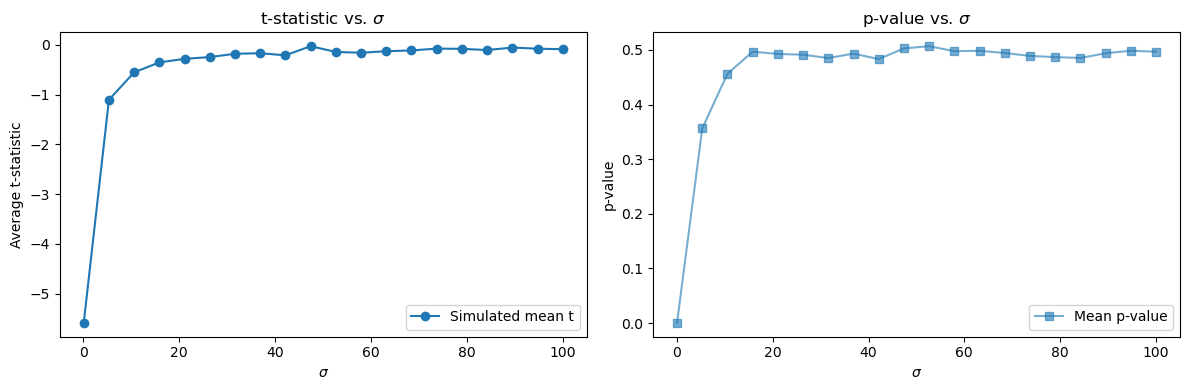

We can see based on the plot and the table, that as the value of sigma increases, the t-statistic approaches 0 and the p-value increases


In [5]:
# Question 1C

print(f"Intuitive Prediction: As sigma increases, the t-stat goes toward 0 and p-value increases")

sigmas = np.linspace(.05, 100, 20)
reps = 1000

rows = []
for s in sigmas:
    x_sim = rng.normal(0, 1, size=(reps, n))
    y_sim = rng.normal(mu, s, size=(reps, n))
    t_sim, p_sim = stats.ttest_ind(x_sim, y_sim, axis=1, equal_var=False)
    rows.append({
        "sigma": s,
        "mean_t": t_sim.mean(),
        "mean_p": p_sim.mean(),
    })

results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))

t_theory = -mu * np.sqrt(n) / np.sqrt(1 + sigmas ** 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

axes[0].plot(results["sigma"], results["mean_t"], marker="o", label="Simulated mean t")
axes[0].set_xlabel(r"$\sigma$")
axes[0].set_ylabel("Average t-statistic")
axes[0].set_title("t-statistic vs. $\\sigma$")
axes[0].legend()

axes[1].plot(results["sigma"], results["mean_p"], marker="s", alpha=0.6, label="Mean p-value")
axes[1].set_xlabel(r"$\sigma$")
axes[1].set_ylabel("p-value")
axes[1].set_title("p-value vs. $\\sigma$")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"We can see based on the plot and the table, that as the value of sigma increases, the t-statistic approaches 0 and the p-value increases")


    n    mean_t       mean_p
   10 -0.354006 4.877601e-01
  100 -1.011531 3.558247e-01
 1000 -3.149719 2.455398e-02
10000 -9.938209 1.635493e-12


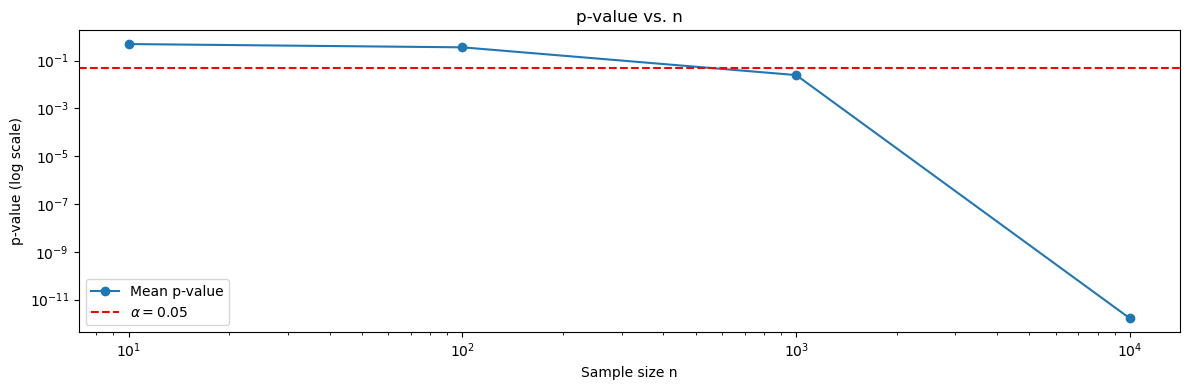

We see that as n increases, the test is able to detect the group difference. However, it takes a very large n to actually get this value as the effect of sigma is large.


In [6]:
# Question 1D

sigma_large = 10
ns = [10, 100, 1000, 10000]
reps = 1000

rows = []
for n_i in ns:
    x_sim = rng.normal(0, 1, size=(reps, n_i))
    y_sim = rng.normal(mu, sigma_large, size=(reps, n_i))
    t_sim, p_sim = stats.ttest_ind(x_sim, y_sim, axis=1, equal_var=False)
    rows.append({
        "n": n_i,
        "mean_t": t_sim.mean(),
        "mean_p": p_sim.mean(),
    })

results_n = pd.DataFrame(rows)
print(results_n.to_string(index=False))


ns_arr = np.array(ns)
t_theory_n = -mu * np.sqrt(ns_arr) / np.sqrt(1 + sigma_large ** 2)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(results_n["n"], results_n["mean_p"], marker="o", label="Mean p-value")
ax.axhline(alpha, color="red", linestyle="--", label=r"$\alpha = 0.05$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Sample size n")
ax.set_ylabel("p-value (log scale)")
ax.set_title("p-value vs. n")
ax.legend()

plt.tight_layout()
plt.show()

print("We see that as n increases, the test is able to detect the group difference. However, it takes a very large n to actually get this value as the effect of sigma is large.")


**Question 1E:**  

A larger σ hurts the Welch t-test: as σ increases, |t| decreases and the p-value increases, because the fixed mean difference (μ = 1) is swamped by noise. This makes the group difference harder to detect, and the expected t shrinks roughly like 1/√(1 + σ²).

A larger sample size n helps: |t| grows like √n and the p-value falls toward 0, because the standard error shrinks as σ/√n. Even at σ = 10, where n = 30 fails to detect the difference, a large enough n does detect it. Sample size doesn't change σ itself. It reduces the noise in the sample means, so a large σ can always be offset with enough data, though it costs roughly (1 + σ²)/2 times as many observations.

Takeaway: a failure to reject at small n and large σ reflects low power, not evidence that the groups are equal.

# Problem 2

**Question 2A:**  

H0: μ_rally = μ_rest
H1: μ_rally > μ_rest

The alternative hypothesis here is one-sided because the problem states a rise during the rally window. This means we need to test if the rally is actually greater than the rest of the year. Our end goal is to see if the rally actually exists or if it is simply a folklore

In [7]:
# Question 2B

import os
import pandas as pd
import yfinance as yf

DATA_FILE = "historical_data.csv"

if os.path.exists(DATA_FILE):
    prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True)
else:
    raw = yf.download("^GSPC", start="1949-12-01", end="2026-02-01", auto_adjust=False)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    prices = raw[["Close"]].copy()
    prices.index.name = "Date"
    prices.to_csv(DATA_FILE)

prices["Return"] = prices["Close"].pct_change()
prices = prices.dropna(subset=["Return"])

print("First rows:")
print(prices.head())
print("\nLast rows:")
print(prices.tail())
print(f"\nNumber of trading days: {len(prices)}")
print(f"Date range: {prices.index.min().date()} to {prices.index.max().date()}")

First rows:
                Close    Return
Date                           
1949-12-02  16.280001  0.008050
1949-12-05  16.410000  0.007985
1949-12-06  16.389999 -0.001219
1949-12-07  16.430000  0.002441
1949-12-08  16.430000  0.000000

Last rows:
                  Close    Return
Date                             
2026-01-26  6950.229980  0.005006
2026-01-27  6978.600098  0.004082
2026-01-28  6978.029785 -0.000082
2026-01-29  6969.009766 -0.001293
2026-01-30  6939.029785 -0.004302

Number of trading days: 19161
Date range: 1949-12-02 to 2026-01-30


In [8]:
# Question 2C1

import numpy as np

all_days = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).index
cal = pd.DataFrame(index=all_days)
cal["year"] = all_days.year
cal["month"] = all_days.month
cal["start_rank"] = cal.groupby("year").cumcount() + 1                   
cal["end_rank"] = cal.groupby("year").cumcount(ascending=False) + 1      

in_jan_part = (cal["month"] == 1) & (cal["start_rank"] <= 2)
in_dec_part = (cal["month"] == 12) & (cal["end_rank"] <= 5)
cal["window_year"] = np.where(in_jan_part, cal["year"] - 1, np.where(in_dec_part, cal["year"], np.nan))

daily = cal.join(prices[["Close", "Return"]], how="inner")

rally_df = daily[daily["window_year"].between(1950, 2025)].copy()
rally_df["year"] = rally_df["window_year"].astype(int)
rally_df = rally_df[["year", "Close", "Return"]]

rest_df = daily[daily["window_year"].isna() & daily["year"].between(1950, 2025)].copy()
rest_df = rest_df[["year", "Close", "Return"]]

print("Rally window (W_t):")
print(rally_df.head())
print(f"Number of trading days in rally windows: {len(rally_df)} ({rally_df['year'].nunique()} years x 7 days)")

print("\nRest of the year (R_t):")
print(rest_df.head())
print(f"Number of trading days in rest of year: {len(rest_df)}")

Rally window (W_t):
            year      Close    Return
Date                                 
1950-12-22  1950  20.070000  0.004505
1950-12-26  1950  19.920000 -0.007474
1950-12-27  1950  20.299999  0.019076
1950-12-28  1950  20.379999  0.003941
1950-12-29  1950  20.430000  0.002453
Number of trading days in rally windows: 532 (76 years x 7 days)

Rest of the year (R_t):
            year      Close    Return
Date                                 
1950-01-05  1950  16.930000  0.004748
1950-01-06  1950  16.980000  0.002953
1950-01-09  1950  17.080000  0.005889
1950-01-10  1950  17.030001 -0.002927
1950-01-11  1950  17.090000  0.003523
Number of trading days in rest of year: 18589


In [9]:
# Question 2C2

yearly_df = pd.DataFrame({
    "rally_mean": rally_df.groupby("year")["Return"].mean(),
    "rest_mean": rest_df.groupby("year")["Return"].mean(),
})

print("First five years:")
print(yearly_df.head())
print("\nLast five years:")
print(yearly_df.tail())
print(f"\nNumber of years: {len(yearly_df)}")

print("It's important to use the per-day average instead of the total return over each set because the number of days between the rally and the rest of the year is disproportionate. \nThere are only 7 days in the rally whereas there is 245 days in the rest of the year. This means the rest of the year has moretime for the stocks to grow and therefore the total value might be much higher than the rally period.\nThis means even if the rally performs better than the rest of the year in per-day average, by using a total return over the year will make the rally look much worse than what it actually was.")

First five years:
      rally_mean  rest_mean
year                       
1950    0.005042   0.000749
1951    0.002240   0.000551
1952    0.002549   0.000393
1953    0.002368  -0.000296
1954    0.004238   0.001418

Last five years:
      rally_mean  rest_mean
year                       
2021    0.002051   0.001004
2022    0.001180  -0.000810
2023   -0.001259   0.000894
2024   -0.000719   0.001007
2025   -0.000151   0.000691

Number of years: 76
It's important to use the per-day average instead of the total return over each set because the number of days between the rally and the rest of the year is disproportionate. 
There are only 7 days in the rally whereas there is 245 days in the rest of the year. This means the rest of the year has moretime for the stocks to grow and therefore the total value might be much higher than the rally period.
This means even if the rally performs better than the rest of the year in per-day average, by using a total return over the year will make the rall

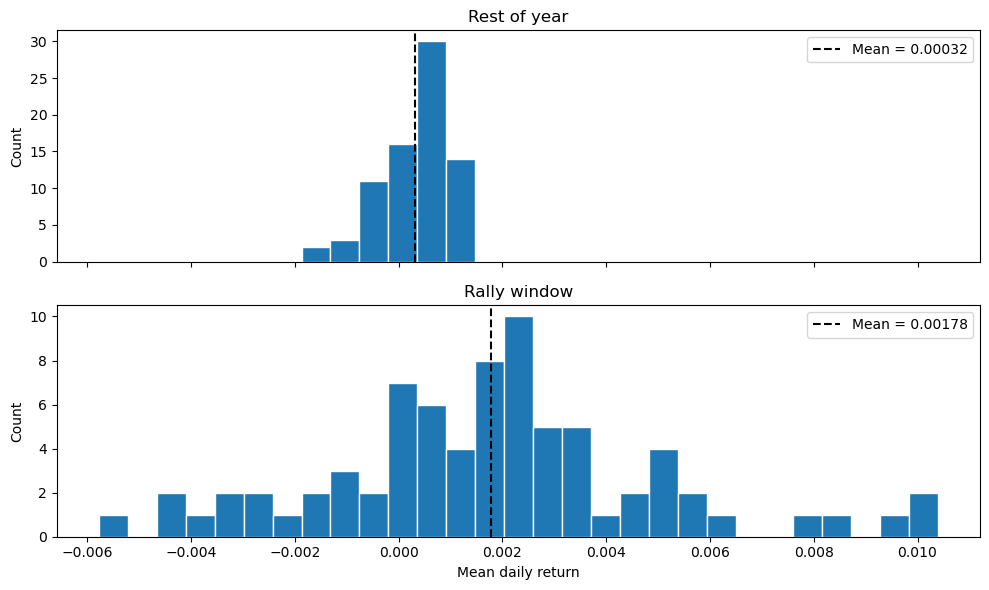

The rally window histogram is much more spread out than the rest of the year. This makes sense because the rally mean is only an average over 7 days, so some few big days move it a lot, whereas each rest of year mean averages about 245 days. The mean of the rally window is also higher than the mean of the rest of the year.


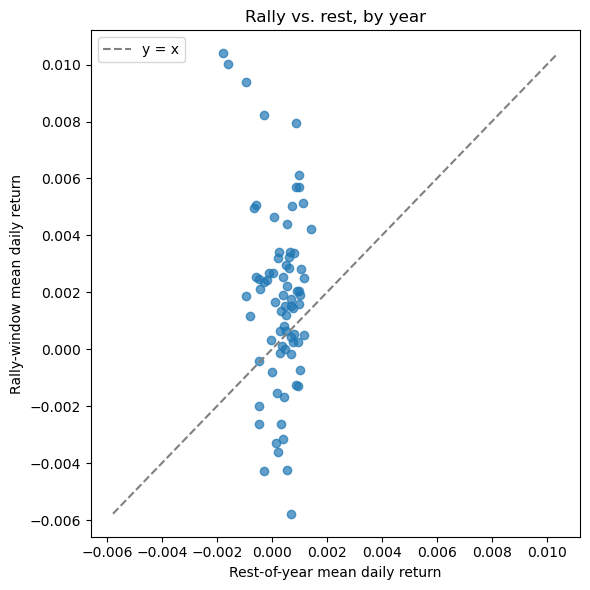

Most of the points sit above the y = x line, meaning the rally window had a higher mean daily return than the rest of the year in most years. The vertical spread is much larger than the horizontal spread, again showing the rally window is more variable. There also seem to be some very good years in the rally, with a few points far above the rest of the cloud.


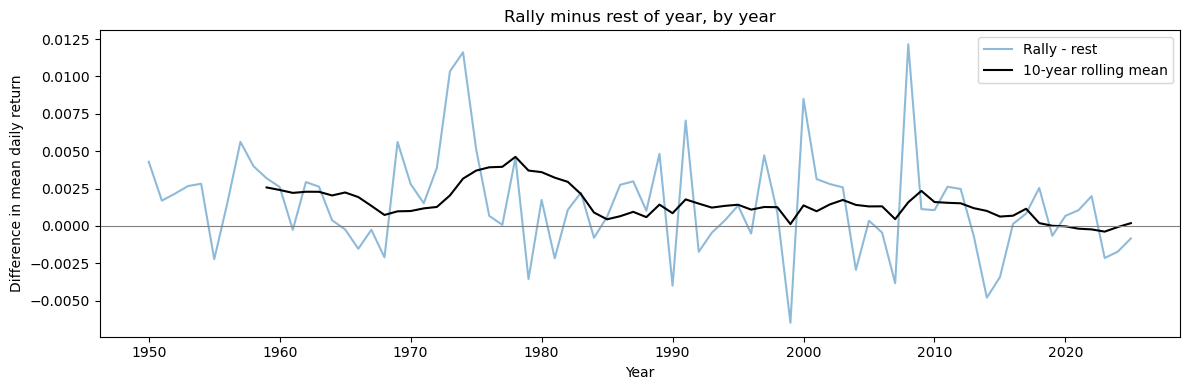

For the most part the difference between the rally and the rest of the year is positive, so the rally window usually did better. However, in recent years the rolling mean has dropped to close to 0 and sometimes goes negative, so the rally period has become negligible compared to the rest of the year.


In [10]:
# Question 2D

rally = yearly_df["rally_mean"]
rest = yearly_df["rest_mean"]

bins = np.linspace(min(rally.min(), rest.min()), max(rally.max(), rest.max()), 30)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, data, label in zip(axes, [rest, rally], ["Rest of year", "Rally window"]):
    ax.hist(data, bins=bins, edgecolor="white")
    ax.axvline(data.mean(), color="black", linestyle="--", label=f"Mean = {data.mean():.5f}")
    ax.set_title(label)
    ax.set_ylabel("Count")
    ax.legend()
axes[1].set_xlabel("Mean daily return")
plt.tight_layout()
plt.show()

print("The rally window histogram is much more spread out than the rest of the year. This makes sense because the rally mean is only an average over 7 days, so some few big days move it a lot, whereas each rest of year mean averages about 245 days. The mean of the rally window is also higher than the mean of the rest of the year.")


lims = [min(rally.min(), rest.min()), max(rally.max(), rest.max())]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(rest, rally, alpha=0.7)
ax.plot(lims, lims, color="gray", linestyle="--", label="y = x")
ax.set_xlabel("Rest-of-year mean daily return")
ax.set_ylabel("Rally-window mean daily return")
ax.set_title("Rally vs. rest, by year")
ax.legend()
plt.tight_layout()
plt.show()

print("Most of the points sit above the y = x line, meaning the rally window had a higher mean daily return than the rest of the year in most years. The vertical spread is much larger than the horizontal spread, again showing the rally window is more variable. There also seem to be some very good years in the rally, with a few points far above the rest of the cloud.")


diff = rally - rest

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(diff.index, diff, alpha=0.5, label="Rally - rest")
ax.plot(diff.index, diff.rolling(10).mean(), color="black", label="10-year rolling mean")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Year")
ax.set_ylabel("Difference in mean daily return")
ax.set_title("Rally minus rest of year, by year")
ax.legend()
plt.tight_layout()
plt.show()

print("For the most part the difference between the rally and the rest of the year is positive, so the rally window usually did better. However, in recent years the rolling mean has dropped to close to 0 and sometimes goes negative, so the rally period has become negligible compared to the rest of the year.")


**Question 2E1:**  
Paired t-test is more appropriate because each year gives a rally and a rest of the year mean value from the same market. The rally also has a larger variance than the rest of the year so using a paired t-test would help avoid any biases that may be introduced by variances.

In [11]:
# Question 2E2

welch_t, welch_p = stats.ttest_ind(rally, rest, equal_var=False, alternative="greater")
paired_t, paired_p = stats.ttest_rel(rally, rest, alternative="greater")
corr = rally.corr(rest)

print(f"Welch:  t = {welch_t:.4f}, p = {welch_p:.4g}")
print(f"Paired: t = {paired_t:.4f}, p = {paired_p:.4g}")
print(f"Correlation (rest, rally): {corr:.4f}")


Welch:  t = 3.8846, p = 0.0001041
Paired: t = 3.7244, p = 0.0001884
Correlation (rest, rally): -0.2265


**Question 2E3:**  
I was surprised that the correlation was negative since I expected a positive correlation (both numbers are coming in the same year). The negative correlation means that the years with high rest of the year returns are having weaker rally windows. This also means that the paired t-test performed slightly worse than the Welch's test. We can see this through our results having a smaller p-value in the Welch's test than in the paired t-test.

In [14]:
# Question 2F

early_df = yearly_df.loc[1950:1987]
late_df = yearly_df.loc[1988:2025]

print(f"Early period (1950-1987): {len(early_df)} years")
print(early_df.head())
print(early_df.tail())
print(f"\nLate period (1988-2025): {len(late_df)} years")
print(late_df.tail())

periods = {"Full (1950-2025)": yearly_df, "1950-1987": early_df, "1988-2025": late_df}

rows = {}
for name, d in periods.items():
    welch_t, welch_p = stats.ttest_ind(d["rally_mean"], d["rest_mean"], equal_var=False, alternative="greater")
    paired_t, paired_p = stats.ttest_rel(d["rally_mean"], d["rest_mean"], alternative="greater")
    rows[name] = {
        "mean rally": d["rally_mean"].mean(),
        "mean rest": d["rest_mean"].mean(),
        "correlation": d["rally_mean"].corr(d["rest_mean"]),
        "Welch t": welch_t,
        "Welch p": welch_p,
        "paired t": paired_t,
        "paired p": paired_p,
    }

print(pd.DataFrame(rows).round(6))

print("I wasn't surprised at these results since I expected the paired t-test to perform better than the Welch's test. Moreover, the market had a lot of corrections during 1988 to 2025 so seeing some negative results and overall lower returns seems accurate and in line with my expectations.\nThe rally effect does not seem to be stable over time as we can see that the difference between the rally and the rest of the year is very close to each other compared to the earlier time block.\nHowever, one thing notable is that the 1988-2025 period still has primarily positive differences so when the rally period comes this year, I should look to buying some stocks and selling high!")

Early period (1950-1987): 38 years
      rally_mean  rest_mean
year                       
1950    0.005042   0.000749
1951    0.002240   0.000551
1952    0.002549   0.000393
1953    0.002368  -0.000296
1954    0.004238   0.001418
      rally_mean     rest_mean
year                          
1983    0.002841  6.267357e-04
1984   -0.000794  9.462715e-07
1985    0.001593  9.878158e-04
1986    0.003423  6.755750e-04
1987    0.003215  2.357025e-04

Late period (1988-2025): 38 years
      rally_mean  rest_mean
year                       
2021    0.002051   0.001004
2022    0.001180  -0.000810
2023   -0.001259   0.000894
2024   -0.000719   0.001007
2025   -0.000151   0.000691
             Full (1950-2025)  1950-1987  1988-2025
mean rally           0.001776   0.002391   0.001161
mean rest            0.000324   0.000263   0.000385
correlation         -0.226535  -0.227248  -0.202331
Welch t              3.884600   4.443548   1.379265
Welch p              0.000104   0.000033   0.087768
paired t 

**Generative AI Use:**  

In this assignment, I primarily used AI to help with plotting. I struggle to do all the plotting work by hand as there are a lot of components that go into making a plot look neat. Claude was able to help me in this and make it so that I can make my plots look nice while also fixing any syntax errors I had.